In [1]:
import pandas as pd
import numpy as np

def load_data(file_path):
    return pd.read_csv(file_path, sep=';', header=None, names=['Text', 'Emotion'])

In [2]:
train_df = load_data('archive-3/train.txt')
val_df = load_data('archive-3/val.txt')
test_df = load_data('archive-3/test.txt')

In [3]:
print("Train shape:", train_df.shape)

Train shape: (16000, 2)


In [4]:
train_df.head()

,Text,Emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [6]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [7]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/saurabh/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/saurabh/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [8]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    words = text.split()
    return ' '.join([lemmatizer.lemmatize(w) for w in words if w not in stop_words])

train_df['Cleaned'] = train_df['Text'].apply(clean_text)
val_df['Cleaned'] = val_df['Text'].apply(clean_text)
test_df['Cleaned'] = test_df['Text'].apply(clean_text)

In [9]:
encoder = LabelEncoder()
y_train = encoder.fit_transform(train_df['Emotion'])
y_val = encoder.transform(val_df['Emotion'])
y_test = encoder.transform(test_df['Emotion'])
num_classes = len(encoder.classes_)

In [10]:
max_words = 10000
max_len = 100

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(train_df['Cleaned'])

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(train_df['Cleaned']), maxlen=max_len, padding='post', truncating='post')
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(val_df['Cleaned']), maxlen=max_len, padding='post', truncating='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(test_df['Cleaned']), maxlen=max_len, padding='post', truncating='post')

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Bidirectional, Dense, Dropout

def build_model(model_type, units=64):
    model = Sequential()
    model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
    
    if model_type == 'simple_rnn':
        model.add(SimpleRNN(units))
    elif model_type == 'lstm':
        model.add(LSTM(units))
    elif model_type == 'gru':
        model.add(GRU(units))
    elif model_type == 'bi_lstm':
        model.add(Bidirectional(LSTM(units)))
    elif model_type == 'stacked_lstm':
        model.add(LSTM(units, return_sequences=True))
        model.add(LSTM(units))
        
    model.add(Dense(64, activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation='softmax'))
    
    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

In [12]:
dl_models = {
    "Simple RNN": 'simple_rnn',
    "LSTM": 'lstm',
    "GRU": 'gru',
    "Bidirectional LSTM": 'bi_lstm',
    "Stacked LSTM": 'stacked_lstm'
}

dl_history = {}
dl_trained = {}

for name, m_type in dl_models.items():
    print(f"\n--- Training {name} ---")
    model = build_model(m_type)
    history = model.fit(
        X_train_seq, y_train,
        validation_data=(X_val_seq, y_val),
        epochs=3,
        batch_size=64,
        verbose=1
    )
    dl_history[name] = history
    dl_trained[name] = model


--- Training Simple RNN ---


/Users/saurabh/Documents/NLP_RNN_Assignmenet/myenv/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.3171 - loss: 1.6064 - val_accuracy: 0.3520 - val_loss: 1.5805
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.3266 - loss: 1.5871 - val_accuracy: 0.3520 - val_loss: 1.5883
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 5s 21ms/step - accuracy: 0.3258 - loss: 1.5843 - val_accuracy: 0.3520 - val_loss: 1.5804

--- Training LSTM ---
Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 17s 63ms/step - accuracy: 0.3219 - loss: 1.5982 - val_accuracy: 0.3520 - val_loss: 1.5825
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 54ms/step - accuracy: 0.3281 - loss: 1.5839 - val_accuracy: 0.3520 - val_loss: 1.5810
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 55ms/step - accuracy: 0.3258 - loss: 1.5823 - val_accuracy: 0.3520 - val_loss: 1.5813

--- Training GRU ---
Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 15s 56ms/step - accuracy: 0.3175 - loss: 1.5988 - val_accuracy: 0.3520 - val_loss: 1.5821
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 14s 55ms/step - 

In [15]:
import keras_tuner as kt

def model_builder(hp):
    model = Sequential()
    model.add(Embedding(input_dim=max_words, output_dim=128, input_length=max_len))
    
    units = hp.Choice('units', values=[32, 64, 128])
    model.add(Bidirectional(LSTM(units=units)))
    
    model.add(Dense(units=hp.Choice('dense_units', values=[32, 64]), activation='relu'))
    model.add(Dropout(0.3))
    model.add(Dense(num_classes, activation='softmax'))
    
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=hp_learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

tuner = kt.Hyperband(model_builder,
                     objective='val_accuracy',
                     max_epochs=3,
                     factor=3,
                     directory='tuner_dir',
                     project_name='emotion_tuning')

tuner.search(X_train_seq, y_train, epochs=3, validation_data=(X_val_seq, y_val), verbose=1)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"\nOptimal units: {best_hps.get('units')}, optimal learning rate: {best_hps.get('learning_rate')}")

tuned_model = tuner.hypermodel.build(best_hps)
tuned_history = tuned_model.fit(X_train_seq, y_train, epochs=3, validation_data=(X_val_seq, y_val), verbose=1)

Reloading Tuner from tuner_dir/emotion_tuning/tuner0.json

Optimal units: 64, optimal learning rate: 0.01
Epoch 1/3
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 51ms/step - accuracy: 0.7972 - loss: 0.5628 - val_accuracy: 0.9250 - val_loss: 0.2038
Epoch 2/3
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 54ms/step - accuracy: 0.9371 - loss: 0.1615 - val_accuracy: 0.9200 - val_loss: 0.2154
Epoch 3/3
500/500 ━━━━━━━━━━━━━━━━━━━━ 27s 55ms/step - accuracy: 0.9444 - loss: 0.1372 - val_accuracy: 0.9095 - val_loss: 0.2384


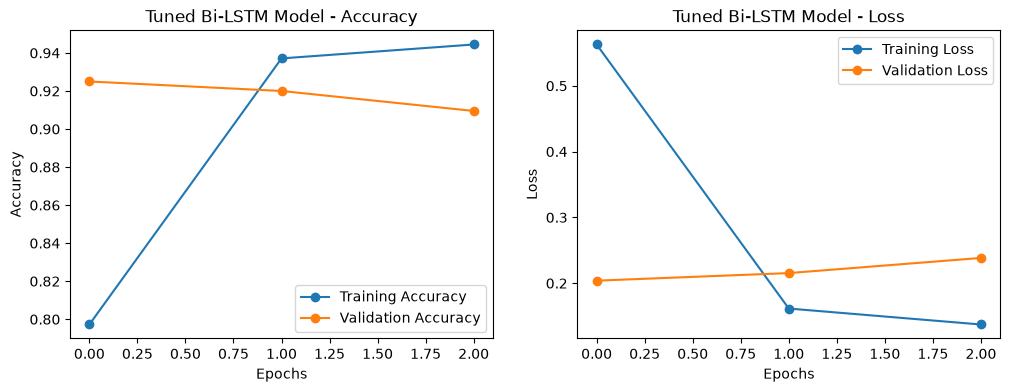

In [22]:
import matplotlib.pyplot as plt

def plot_loss_curves(history, model_name):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    
    epochs = range(len(acc))
    
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy', marker='o')
    plt.plot(epochs, val_acc, label='Validation Accuracy', marker='o')
    plt.legend()
    plt.title(f'{model_name} - Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss', marker='o')
    plt.plot(epochs, val_loss, label='Validation Loss', marker='o')
    plt.legend()
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    
    plt.show()

# Visualize performance metrics for the tuned model
plot_loss_curves(tuned_history, "Tuned Bi-LSTM Model")

In [24]:
from sklearn.metrics import accuracy_score, f1_score

results = []

for name, model in dl_trained.items():
    preds = model.predict(X_test_seq)
    y_pred_classes = preds.argmax(axis=-1) if preds.ndim > 1 else (preds > 0.5).astype(int)
    
    acc = accuracy_score(y_test, y_pred_classes)
    f1 = f1_score(y_test, y_pred_classes, average='weighted')
    
    results.append({
        "Model": name, 
        "Accuracy (%)": round(acc * 100, 2), 
        "F1-Score (%)": round(f1 * 100, 2)
    })

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step


In [25]:
tuned_preds = tuned_model.predict(X_test_seq).argmax(axis=-1)
tuned_acc = accuracy_score(y_test, tuned_preds)
tuned_f1 = f1_score(y_test, tuned_preds, average='weighted')

results.append({
    "Model": "Tuned Bi-LSTM (Optimized)", 
    "Accuracy (%)": round(tuned_acc * 100, 2), 
    "F1-Score (%)": round(tuned_f1 * 100, 2)
})

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step


In [26]:
results_df = pd.DataFrame(results).sort_values(by="Accuracy (%)", ascending=False).reset_index(drop=True)

In [27]:
print("\n=== Deep Learning Model Performance Comparison Table ===")
display(results_df)


=== Deep Learning Model Performance Comparison Table ===


,Model,Accuracy (%),F1-Score (%)
0,Tuned Bi-LSTM (Optimized),91.15,90.95
1,Bidirectional LSTM,90.65,90.65
2,Simple RNN,34.75,17.92
3,LSTM,34.75,17.92
4,GRU,34.75,17.92
5,Stacked LSTM,34.75,17.92


In [30]:
best_row = results_df.iloc[0]
print(f"\n Suggested Best Model: {best_row['Model']} with an Accuracy of {best_row['Accuracy (%)']}% and F1-Score of {best_row['F1-Score (%)']}%.")


 Suggested Best Model: Tuned Bi-LSTM (Optimized) with an Accuracy of 91.15% and F1-Score of 90.95%.
